# Study 03 — Particle Swarm Optimisation (PSO)

Exploratory study notebook: before wiring PSO into the full experiment system, we check that it works,
learn how its hyper-parameters behave on our tuning problem, and see how it copes with every controller and plant.

**Questions**
1. Does the implementation actually optimise? (benchmark functions with known optimum)
2. Which hyper-parameters matter for controller tuning, and how much?
3. With a fixed evaluation budget, is it better to have a big population or many generations?
4. How well does it tune each controller on each plant — and where does it fail?

All runs use the project's own simulator, metrics and objective through
`smart_control.experiments.runner.run_single_experiment`. Only `numpy`, `matplotlib` and `control` are used.
⏱ Full run: about 5 minutes on a laptop.

## The algorithm

**Idea.** Each particle has a position $x$ and velocity $v$; it is pulled toward its own best
position $p_{best}$ and the swarm's best $g_{best}$:
$$v \leftarrow w\,v + c_1 r_1 (p_{best}-x) + c_2 r_2 (g_{best}-x), \qquad x \leftarrow x + v .$$
The velocity is clamped to `v_max_ratio` × (range) so particles cannot fly out of the search space in one step.

Hyper-parameters to study: inertia **w** (memory of the previous direction) and the acceleration
coefficients **c₁ = c₂** (how strongly particles are pulled toward the bests), then the velocity clamp.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from study_utils import *          # project import, runners, benchmarks, plots
from smart_control.optimizers.particle_swarm import ParticleSwarmOptimization

KEY, COLOR = "PSO", OPT_COLORS["PSO"]
print("Implementation defaults:")
for k, v in ParticleSwarmOptimization().default_settings().items():
    print(f"  {k:22s} {v}")

Implementation defaults:
  population_size        30
  max_iterations         100
  inertia_weight         0.7
  cognitive_coeff        1.5
  social_coeff           1.5
  v_max_ratio            0.2
  random_seed            42


## 1. Sanity check on benchmark functions

Before tuning controllers, make sure PSO minimises functions whose optimum we know (all have minimum 0):
**Sphere** (one smooth bowl), **Rastrigin** (a grid of local minima) and **Rosenbrock** (a curved, narrow valley),
in 2, 5 and 10 dimensions, with ≈500 evaluations and 3 seeds.

In [2]:
bench = benchmark_runs(ParticleSwarmOptimization, budget(KEY, 20, 24))
benchmark_table(bench)

Function     dim  best f (mean of seeds)  worst seed
Sphere         2               9.456e-07   1.702e-06
Sphere         5               0.0004282   0.0009006
Sphere        10                 0.06289     0.08508
Rastrigin      2                0.004678     0.01179
Rastrigin      5                   3.875       6.327
Rastrigin     10                   22.07        34.6
Rosenbrock     2                 0.02329     0.06837
Rosenbrock     5                   3.512       4.167
Rosenbrock    10                   9.329       10.38


Where does it sample? Each dot is one objective evaluation on 2-D Rastrigin.

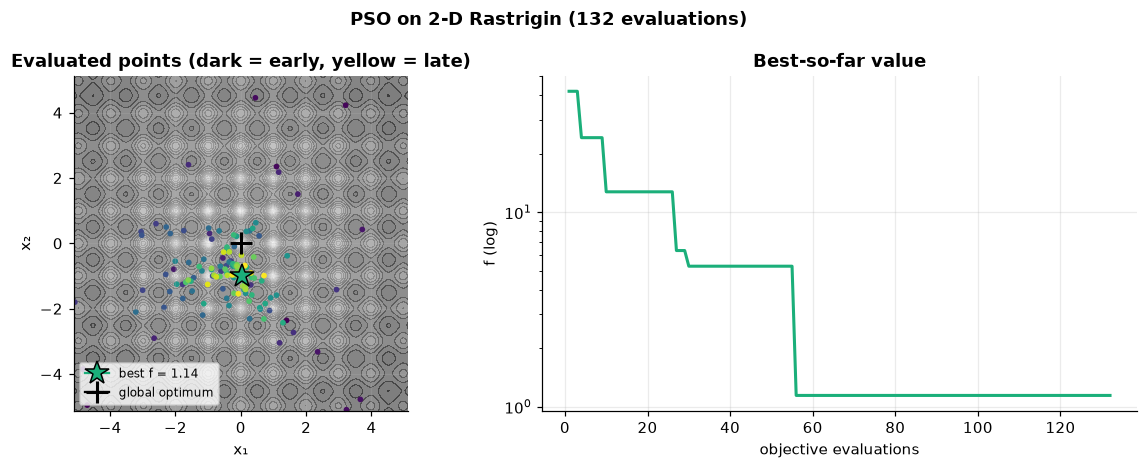

In [3]:
plot_search(ParticleSwarmOptimization, budget(KEY, 12, 10), COLOR, title="PSO on 2-D Rastrigin (132 evaluations)")

## 2. Hyper-parameter study

**Test case:** PID on the 3rd-order plant — cheap to simulate, and sensitive enough to show differences.
Budget ≈60 evaluations, 3 seeds per setting; the heat-map shows **mean J** (± std), best setting outlined.

### 2a. inertia w × c₁ = c₂

27 runs in 44 s


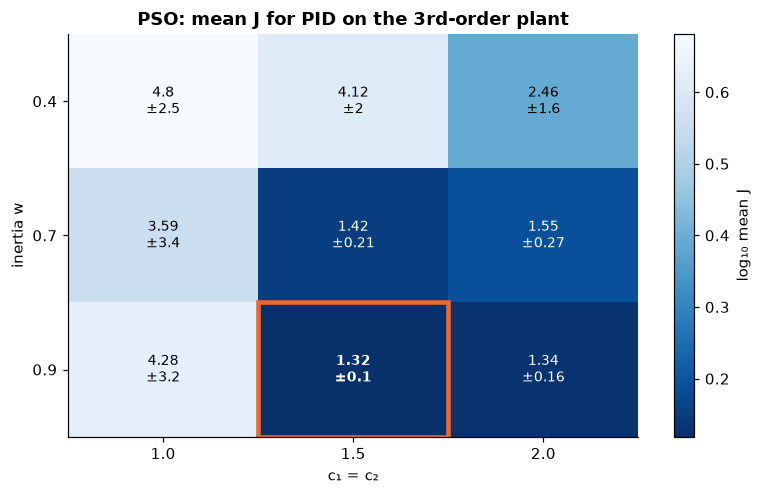

Best: inertia w = 0.9, c₁ = c₂ = 1.5  ->  mean J = 1.315
Worst/best ratio: 3.6x


In [4]:
ROWS, COLS = [0.4, 0.7, 0.9], [1.0, 1.5, 2.0]
mean, std = sweep2d(ParticleSwarmOptimization, budget(KEY, 10, 5), 'inertia_weight', ROWS, ('cognitive_coeff', 'social_coeff'), COLS)
i, j = sweep_heatmap(mean, ROWS, COLS, "inertia w", "c₁ = c₂",
                     "PSO: mean J for PID on the 3rd-order plant", std=std)
print(f"Best: inertia w = {ROWS[i]}, c₁ = c₂ = {COLS[j]}  ->  mean J = {mean[i, j]:.4g}")
print(f"Worst/best ratio: {mean.max() / mean.min():.1f}x")

### 2b. v_max ratio

A tight clamp makes the swarm cautious; a loose one lets particles overshoot good regions.

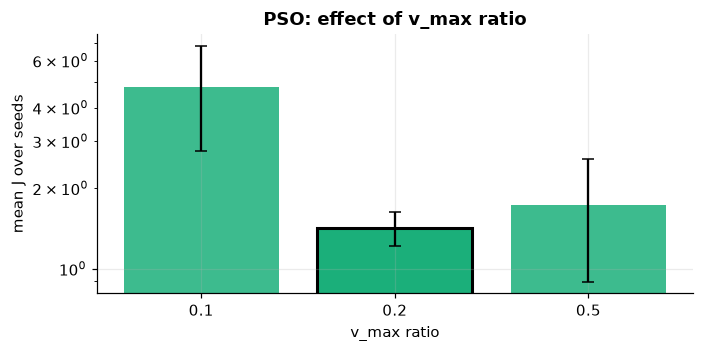

v_max ratio =    0.1   mean J = 4.774 ± 2
v_max ratio =    0.2   mean J = 1.418 ± 0.21
v_max ratio =    0.5   mean J = 1.733 ± 0.84


In [5]:
VALUES = [0.1, 0.2, 0.5]
m1, s1 = sweep1d(ParticleSwarmOptimization, budget(KEY, 10, 5), 'v_max_ratio', VALUES)
plot_sweep1d(VALUES, m1, s1, "v_max ratio", COLOR, "PSO: effect of v_max ratio")
for v, m, sd in zip(VALUES, m1, s1):
    print(f"v_max ratio = {v!s:>6}   mean J = {m:.4g} ± {sd:.2g}")

## 3. Population vs generations at a fixed budget

Every split below costs exactly **120 evaluations** (P × (1 + G)). Few large generations explore more;
many small generations exploit more. PID on the 3rd-order plant, 3 seeds.

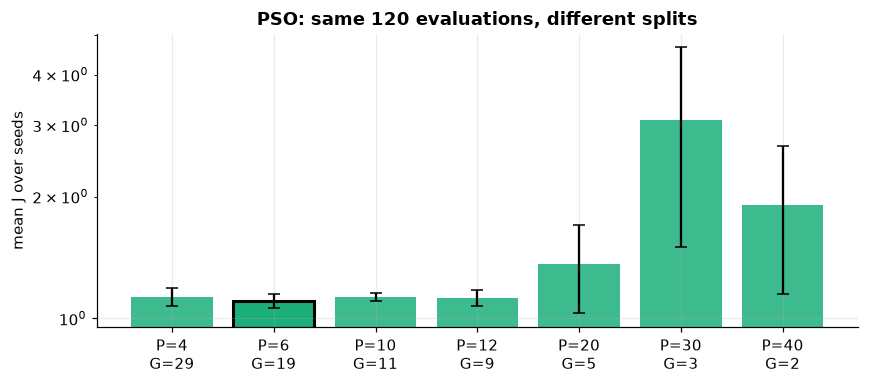

P =  4, G = 29   mean J = 1.132 ± 0.057
P =  6, G = 19   mean J = 1.104 ± 0.046
P = 10, G = 11   mean J = 1.131 ± 0.024
P = 12, G =  9   mean J = 1.126 ± 0.05
P = 20, G =  5   mean J = 1.366 ± 0.34
P = 30, G =  3   mean J = 3.084 ± 1.6
P = 40, G =  2   mean J = 1.908 ± 0.76


In [6]:
SPLITS = [(4, 29), (6, 19), (10, 11), (12, 9), (20, 5), (30, 3), (40, 2)]
means, stds = [], []
for p, g in SPLITS:
    js = [run(ParticleSwarmOptimization, "PID", "third_order", budget(KEY, p, g), seed)["best_fitness"] for seed in (42, 43, 44)]
    means.append(np.mean(js)); stds.append(np.std(js))
plot_budget_split(SPLITS, means, stds, COLOR, "PSO: same 120 evaluations, different splits")
for (p, g), m, sd in zip(SPLITS, means, stds):
    print(f"P = {p:2d}, G = {g:2d}   mean J = {m:.4g} ± {sd:.2g}")

## 4. Every controller on every plant

The real question: **how does PSO do on the actual tuning problems?**

* Budget: population 10 × 5 generations ⇒ **≈60 objective evaluations per run** (the *Extended* budget used in the final system).
* Hyper-parameters: the **implementation defaults** (so these numbers match the final system), not the sweep winners above.
* 3 independent seeds (42, 43, 44) per cell → 4 controllers × 3 plants × 3 seeds = 36 runs.
* Fuzzy runs dominate the runtime (25-rule inference at every simulation step).

In [7]:
records = run_matrix(ParticleSwarmOptimization, list(CONTROLLERS), PLANT_NAMES, budget(KEY, 10, 5), seeds=(42, 43, 44))

PID             2nd order seed 42  J =    0.6119  IAE =   0.388  settled = yes  (1.8 s)


PID             2nd order seed 43  J =     1.378  IAE =   0.271  settled = yes  (1.7 s)


PID             2nd order seed 44  J =    0.5241  IAE =   0.302  settled = yes  (1.8 s)


PID             3rd order seed 42  J =     1.273  IAE =    0.59  settled = yes  (1.5 s)


PID             3rd order seed 43  J =     1.271  IAE =   0.604  settled = yes  (1.9 s)


PID             3rd order seed 44  J =     1.711  IAE =   0.645  settled = yes  (1.8 s)


... (26 outputs left out)

GP Controller   3rd order seed 44  J =     11.48  IAE =    3.85  settled = yes  (1.0 s)


GP Controller   4th order seed 42  J =        33  IAE =    8.66  settled = no   (1.2 s)


GP Controller   4th order seed 43  J =        33  IAE =    8.66  settled = no   (1.6 s)


GP Controller   4th order seed 44  J =     7.146  IAE =    4.23  settled = yes  (1.2 s)

36 runs in 325 s


### Results table
J is mean ± std over seeds; the metric columns are from the best seed.

In [8]:
summary_table(records)

Controller      Plant        J mean    ± std  settled     IAE  Ts (s)  Tr (s)    OS %      Ess
----------------------------------------------------------------------------------------------
PID             2nd order     0.838    0.383     3/3   0.302    0.74   0.442       0 0.000628
PID             3rd order     1.418    0.207     3/3   0.604    2.22    1.09       0  0.00119
PID             4th order     54.59     18.3     0/3    14.2       —       —       0    0.441
Neural Network  2nd order     25.08     5.73     1/3    1.32    6.31   0.861    27.5  0.00685
Neural Network  3rd order     32.89     1.81     0/3     6.2       —       —       0    0.279
Neural Network  4th order     32.18     5.95     1/3    7.05    19.9    2.58    21.4    0.128
Fuzzy           2nd order    0.8617    0.164     3/3   0.485    0.85    0.63       0  0.00286
Fuzzy           3rd order     1.497    0.322     3/3   0.689    1.53    0.79       0  0.00762
Fuzzy           4th order     25.88     9.19     1/3    5.

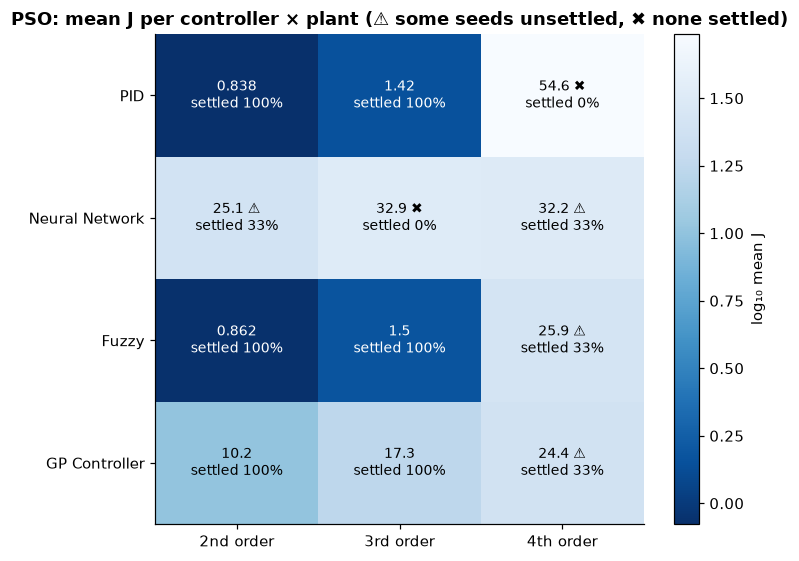

In [9]:
plot_matrix_heatmap(records, "PSO: mean J per controller × plant (⚠ some seeds unsettled, ✖ none settled)")

### Step responses (best seed of each cell)

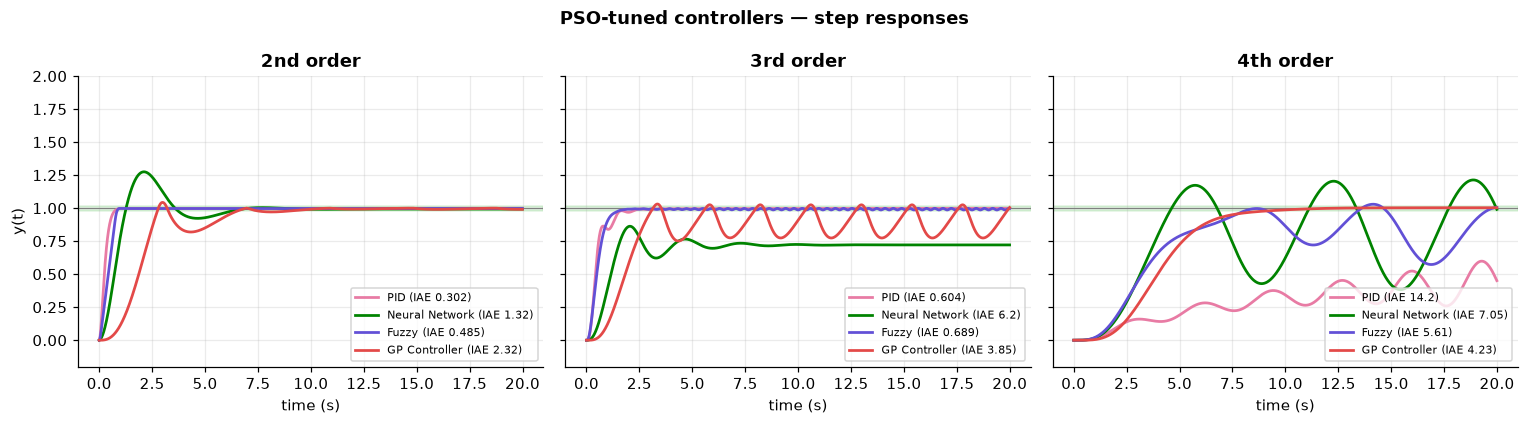

In [10]:
plot_step_grid(records, "PSO-tuned controllers — step responses")

### Convergence
One line per seed; solid = 2nd, dashed = 3rd, dotted = 4th order.

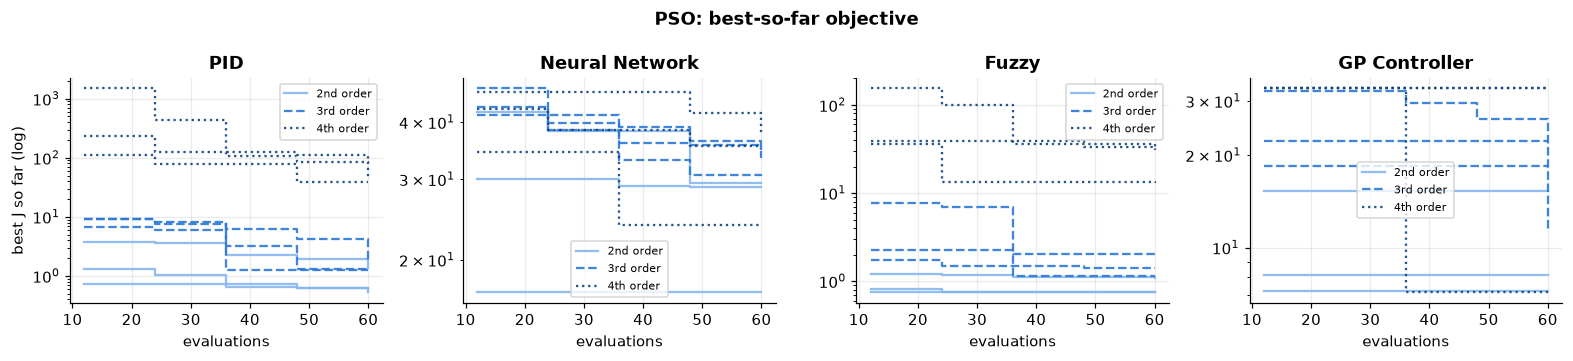

In [11]:
plot_convergence_grid(records, COLOR, "PSO: best-so-far objective")

### Control effort on the 3rd-order plant
A good response is not enough if the actuator has to work unreasonably hard.

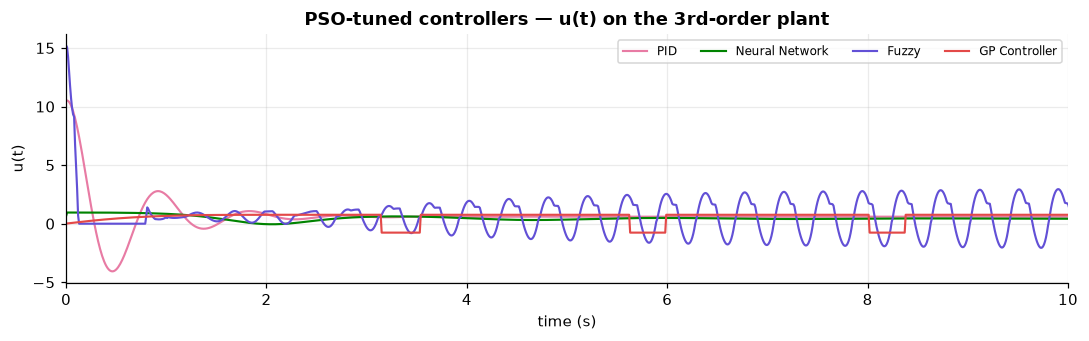

In [12]:
plot_control_effort(records, "third_order", "PSO-tuned controllers — u(t) on the 3rd-order plant")

## Takeaways

**1. Best benchmark performance of the four numeric optimisers — in every dimension.** 10-D Sphere ≈ 0.063 (DE 3.0, GA 16.7, SA 3.4), 10-D Rastrigin ≈ 22 (others 60–73), 10-D Rosenbrock ≈ 9.3 (others 58–314). The search plot shows the swarm collapsing quickly onto a good basin: strong information sharing through g_best.

**2. Hyper-parameters (3.6× spread):** best **inertia w = 0.9 with c₁ = c₂ = 1.5** (J ≈ 1.32). High inertia keeps particles moving long enough to explore when there are only a few iterations. The **velocity clamp matters a lot at the low end**: v_max = 0.1 × range was 3× worse (J ≈ 4.8) — particles cannot cross the PID bounds in time — while the default 0.2 was best.

**3. Budget split: the most robust optimiser.** J ≈ 1.10–1.13 for every split from P = 4 to P = 12 (tiny spread); only very large swarms (P ≥ 20) degrade.

**4. On the real problems (≈60 evals, defaults):**
- **Best and most reliable PID on the 3rd-order plant** among DE/GA (J ≈ 1.42 ± 0.21) and very good PID 2nd order (J ≈ 0.84).
- **Best optimiser for the GP controller**: all seeds settle on the 3rd-order plant (J ≈ 17.3) and one seed even settles on the 4th-order plant — the only numeric optimiser that escapes the J = 33 trap there.
- Fuzzy 2nd/3rd order tuned well (J ≈ 0.86 / 1.50).
- **PID on the 4th-order plant fails on every seed** (J ≈ 55) and the neural network settles in only 2/9 runs — the same structural limits seen with every optimiser.

**Implications for the full system:** PSO is the safest default under a small budget; its defaults are already close to the best settings found here.